# Titanic Dataset - Exploratory Data Analysis (EDA)

## Zepto Data & AI Platform

### Module 2 - Analytics Pipeline (Part A)

This notebook loads the Titanic dataset, performs data profiling, missing value analysis, exploratory data analysis (EDA), and prepares the cleaned dataset for the modeling pipeline.

In [ ]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings("ignore")

In [ ]:
df = sns.load_dataset("titanic")

In [ ]:
df.to_csv("titanic.csv", index=False)

print("Titanic dataset saved successfully!")

Titanic dataset saved successfully!


In [ ]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:
df.shape

(891, 15)

Data Information

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [ ]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
df.shape

(891, 15)

In [ ]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage

,0
survived,0.000000
pclass,0.000000
sex,0.000000
age,19.865320
sibsp,0.000000
parch,0.000000
fare,0.000000
embarked,0.224467
class,0.000000
who,0.000000


In [ ]:
missing_percentage = missing_percentage[missing_percentage > 0]

missing_percentage

,0
age,19.865320
embarked,0.224467
deck,77.216611
embark_town,0.224467


Cleaning

In [ ]:
df_clean = df.copy()

In [ ]:
df_clean = df_clean.drop(columns=["deck"])

In [ ]:
df_clean.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive',
       'alone'],
      dtype='object')

In [ ]:
df_clean = df_clean.dropna(subset=["embarked", "embark_town"])

In [ ]:
df_clean.shape

(889, 14)

In [ ]:
median_age = df_clean["age"].median()

df_clean["age"] = df_clean["age"].fillna(median_age)

In [ ]:
df_clean.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0
class,0
who,0


In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 889 entries, 0 to 890
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     889 non-null    int64   
 1   pclass       889 non-null    int64   
 2   sex          889 non-null    object  
 3   age          889 non-null    float64 
 4   sibsp        889 non-null    int64   
 5   parch        889 non-null    int64   
 6   fare         889 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        889 non-null    category
 9   who          889 non-null    object  
 10  adult_male   889 non-null    bool    
 11  embark_town  889 non-null    object  
 12  alive        889 non-null    object  
 13  alone        889 non-null    bool    
dtypes: bool(2), category(1), float64(2), int64(4), object(5)
memory usage: 86.1+ KB


Histogram of Age

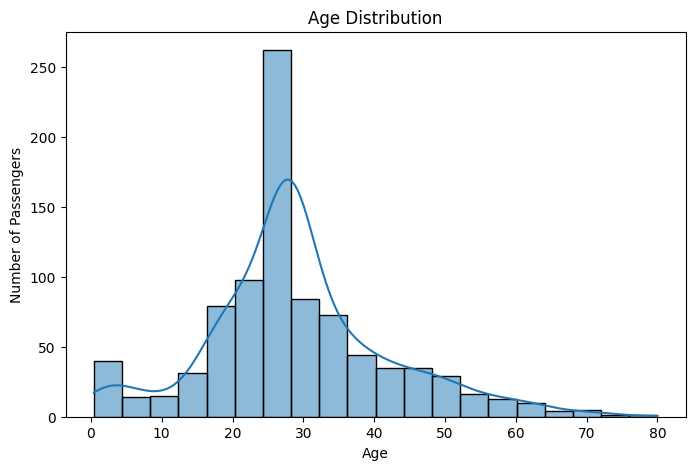

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df_clean["age"], bins=20, kde=True)

plt.title("Age Distribution")

plt.xlabel("Age")

plt.ylabel("Number of Passengers")

plt.show()

Box Plot of Age

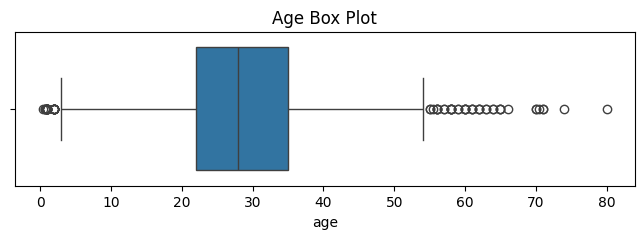

In [ ]:
plt.figure(figsize=(8,2))

sns.boxplot(x=df_clean["age"])

plt.title("Age Box Plot")

plt.show()

Histogram of Fare

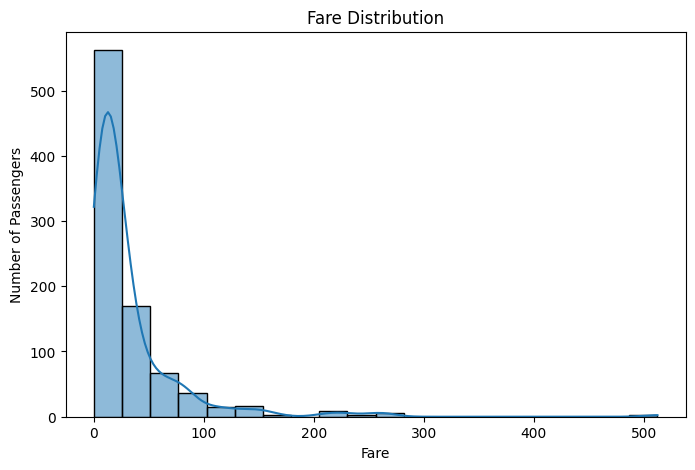

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df_clean["fare"], bins=20, kde=True)

plt.title("Fare Distribution")

plt.xlabel("Fare")

plt.ylabel("Number of Passengers")

plt.show()

Box Plot of Fare

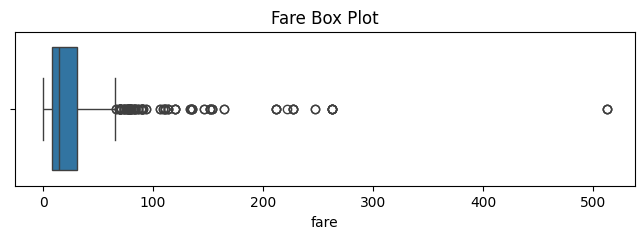

In [ ]:
plt.figure(figsize=(8,2))

sns.boxplot(x=df_clean["fare"])

plt.title("Fare Box Plot")

plt.show()

#IQR Method
Age Outliers

In [ ]:
Q1_age = df_clean["age"].quantile(0.25)
Q3_age = df_clean["age"].quantile(0.75)

IQR_age = Q3_age - Q1_age

lower_age = Q1_age - 1.5 * IQR_age
upper_age = Q3_age + 1.5 * IQR_age

age_outliers = df_clean[
    (df_clean["age"] < lower_age) |
    (df_clean["age"] > upper_age)
]

print("Age Outliers :", len(age_outliers))

Age Outliers : 65


Fare Outliers

In [ ]:
Q1_fare = df_clean["fare"].quantile(0.25)
Q3_fare = df_clean["fare"].quantile(0.75)

IQR_fare = Q3_fare - Q1_fare

lower_fare = Q1_fare - 1.5 * IQR_fare
upper_fare = Q3_fare + 1.5 * IQR_fare

fare_outliers = df_clean[
    (df_clean["fare"] < lower_fare) |
    (df_clean["fare"] > upper_fare)
]

print("Fare Outliers :", len(fare_outliers))

Fare Outliers : 114


Mean, Median, Mode

In [ ]:
fare_mean = df_clean["fare"].mean()
fare_median = df_clean["fare"].median()
fare_mode = df_clean["fare"].mode()[0]

print("Mean   :", fare_mean)
print("Median :", fare_median)
print("Mode   :", fare_mode)


Mean   : 32.09668087739032
Median : 14.4542
Mode   : 8.05


#Bivariate Analysis
Survival Rate by Sex

In [ ]:
male = df_clean[df_clean["sex"] == "male"]

female = df_clean[df_clean["sex"] == "female"]

male_survival = (male["survived"].mean()) * 100

female_survival = (female["survived"].mean()) * 100

print("Male Survival Rate :", round(male_survival,2),"%")

print("Female Survival Rate :", round(female_survival,2),"%")

Male Survival Rate : 18.89 %
Female Survival Rate : 74.04 %


Survival Rate by Passenger Class

In [ ]:
for pclass in sorted(df_clean["pclass"].unique()):

    rate = df_clean[df_clean["pclass"] == pclass]["survived"].mean()*100

    print(f"Class {pclass} Survival Rate :", round(rate,2),"%")

Class 1 Survival Rate : 62.62 %
Class 2 Survival Rate : 47.28 %
Class 3 Survival Rate : 24.24 %


Sex + Passenger Class Together

In [ ]:
for sex in ["male","female"]:

    for pclass in [1,2,3]:

        rate = df_clean[

            (df_clean["sex"] == sex) &

            (df_clean["pclass"] == pclass)

        ]["survived"].mean()*100

        print(f"{sex.title()} - Class {pclass} :", round(rate,2),"%")

Male - Class 1 : 36.89 %
Male - Class 2 : 15.74 %
Male - Class 3 : 13.54 %
Female - Class 1 : 96.74 %
Female - Class 2 : 92.11 %
Female - Class 3 : 50.0 %


#Correlation Matrix & Heatmap
Correlation Matrix

In [ ]:
correlation = df_clean[
    ["survived", "pclass", "age", "sibsp", "parch", "fare"]
].corr()

correlation

,survived,pclass,age,sibsp,parch,fare
survived,1.000000,-0.335549,-0.069822,-0.034040,0.083151,0.255290
pclass,-0.335549,1.000000,-0.336512,0.081656,0.016824,-0.548193
age,-0.069822,-0.336512,1.000000,-0.232543,-0.171485,0.093707
sibsp,-0.034040,0.081656,-0.232543,1.000000,0.414542,0.160887
parch,0.083151,0.016824,-0.171485,0.414542,1.000000,0.217532
fare,0.255290,-0.548193,0.093707,0.160887,0.217532,1.000000


Heatmap

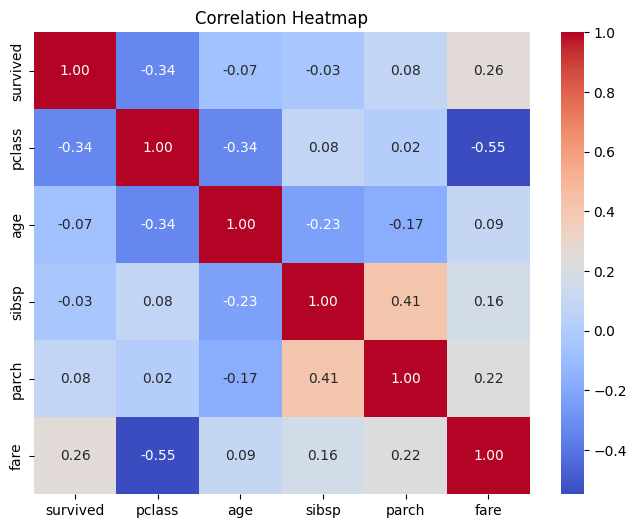

In [ ]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

#Charts + Interpretation
Survival by Sex

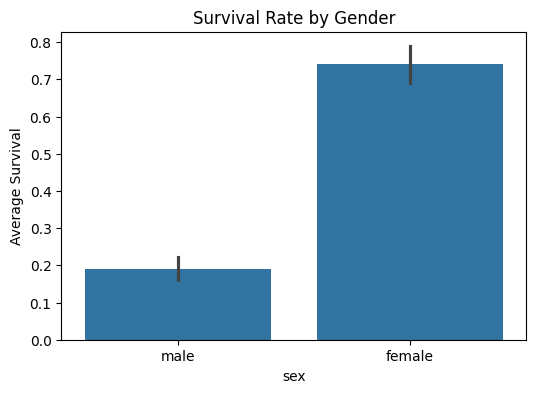

In [ ]:
plt.figure(figsize=(6,4))

sns.barplot(
    data=df_clean,
    x="sex",
    y="survived"
)

plt.title("Survival Rate by Gender")
plt.ylabel("Average Survival")

plt.show()

Survival Rate by Passenger Class

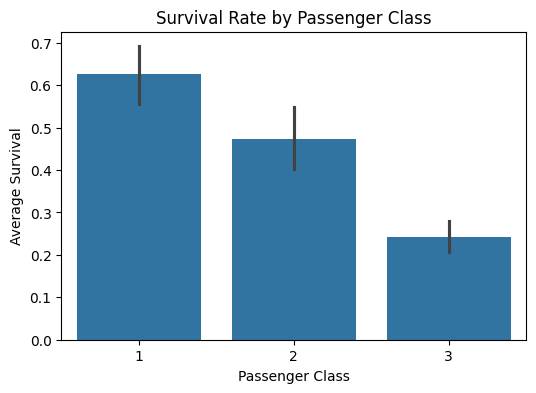

In [ ]:
plt.figure(figsize=(6,4))

sns.barplot(
    data=df_clean,
    x="pclass",
    y="survived"
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Average Survival")

plt.show()

Age vs Survival

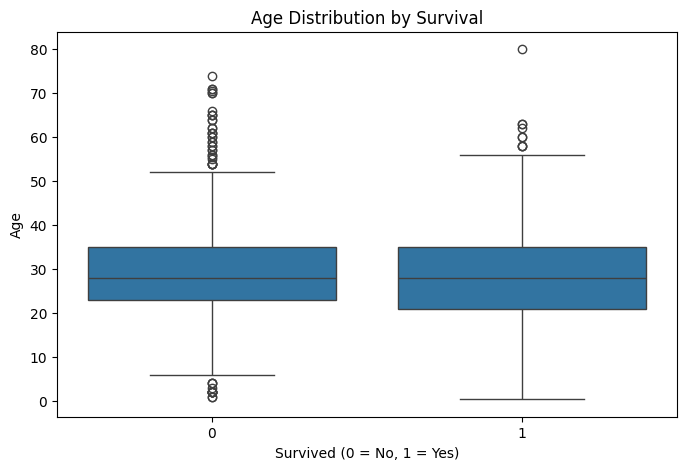

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_clean,
    x="survived",
    y="age"
)

plt.title("Age Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")

plt.show()

Fare vs Survival

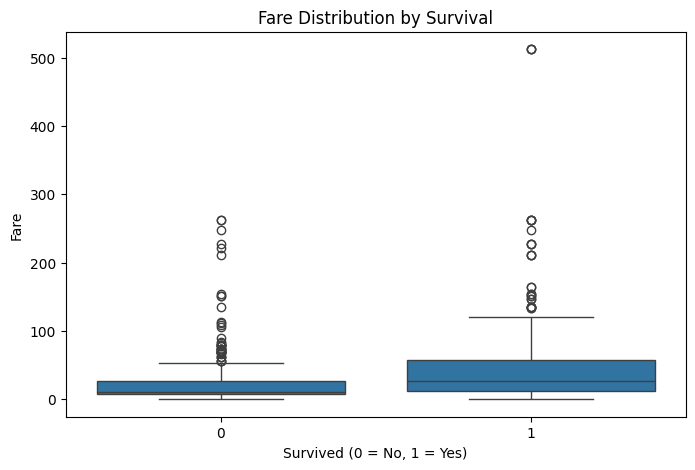

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_clean,
    x="survived",
    y="fare"
)

plt.title("Fare Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Fare")

plt.show()

StandardScaler

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

Standardize Age and Fare

In [ ]:
df_standard = df_clean.copy()

df_standard[["age", "fare"]] = scaler.fit_transform(
    df_standard[["age", "fare"]]
)

Mean and Standard Deviation

In [ ]:
print(df_standard[["age", "fare"]].mean())

print()

print(df_standard[["age", "fare"]].std())

age     2.717486e-16
fare    1.398706e-16
dtype: float64

age     1.000563
fare    1.000563
dtype: float64


Before vs After Comparison

In [ ]:
print("Original")

print(df_clean[["age","fare"]].describe())

print()

print("Standardized")

print(df_standard[["age","fare"]].describe())

Original
              age        fare
count  889.000000  889.000000
mean    29.315152   32.096681
std     12.984932   49.697504
min      0.420000    0.000000
25%     22.000000    7.895800
50%     28.000000   14.454200
75%     35.000000   31.000000
max     80.000000  512.329200

Standardized
                age          fare
count  8.890000e+02  8.890000e+02
mean   2.717486e-16  1.398706e-16
std    1.000563e+00  1.000563e+00
min   -2.226536e+00 -6.462044e-01
25%   -5.636741e-01 -4.872378e-01
50%   -1.013399e-01 -3.551972e-01
75%    4.380499e-01 -2.207954e-02
max    3.905556e+00  9.668551e+00
